# Monte-Carlo-Simulation: Tore bei einem Fußballspiel

## Fragestellung

Angenommen, eine Fußballmannschaft hat in einem Spiel **20 Torschüsse**.
Jeder Torschuss führt mit einer Wahrscheinlichkeit von **12 %** zu einem Tor.

**Frage:**
Wie wahrscheinlich ist es, dass die Mannschaft in diesem Spiel **mindestens 3 Tore** erzielt?

Diese Wahrscheinlichkeit wird mithilfe einer **Monte-Carlo-Simulation** geschätzt. Dabei werden sehr viele Spiele zufällig simuliert und anschließend ausgewertet.

## Idee der Simulation

Für jedes simulierte Spiel gilt:

- Es gibt 20 Torschüsse.
- Jeder Torschuss wird zufällig als Tor oder kein Tor bewertet.
- Die Torwahrscheinlichkeit pro Schuss beträgt 12 %.
- Am Ende wird gezählt, wie viele Tore in einem Spiel gefallen sind.

Danach wird berechnet:

- die Wahrscheinlichkeit für mindestens 3 Tore,
- der Mittelwert der erzielten Tore,
- die Standardabweichung der erzielten Tore,
- eine grafische Darstellung der Ergebnisse.


Durchschnittliche Tore pro Spiel: 2.39846
Gesamte Tore: 239846
Standardabweichung: 1.4543760271676647
Wahrscheinlichkeit für mindestens 3 Tore: 0.4376
Das entspricht: 43.76 %


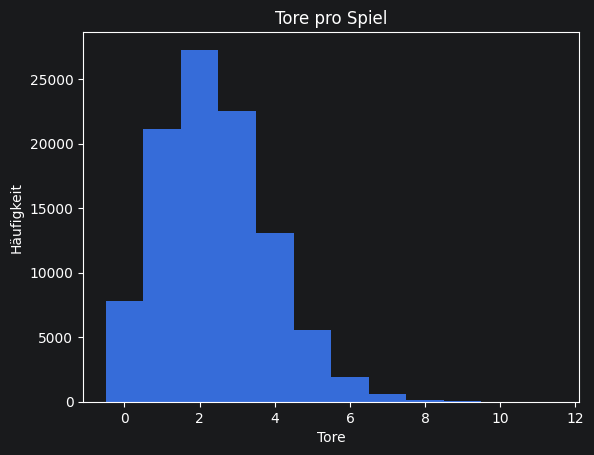

In [9]:
import numpy as np
import matplotlib.pyplot as plt

# 0 -> kein Tor
# 1 -> Tor

n = 10**5                    # Anzahl Simulationen
torschuesse = 20             # Torschüsse pro Spiel
tor_wahrscheinlichkeit = 0.12 # 12 %

data = np.random.choice(np.arange(0, 2), size=(n, torschuesse), p=[1 - tor_wahrscheinlichkeit, tor_wahrscheinlichkeit])

gesamtTore = 0
anzahlMindestens3Tore = 0

toreProSpiel = []

for i in range(n):
    tore = 0
    for j in range(torschuesse):
        if data[i][j] == 1:
            tore += 1
    toreProSpiel.append(tore)
    gesamtTore += tore
    if tore >= 3:
        anzahlMindestens3Tore += 1

durchschnittTore = gesamtTore / n
wahrscheinlichkeitMindestens3 = anzahlMindestens3Tore / n
standardabweichung = np.std(toreProSpiel)

print(f"Durchschnittliche Tore pro Spiel: {durchschnittTore}")
print(f"Gesamte Tore: {gesamtTore}")
print(f"Standardabweichung: {standardabweichung}")
print(f"Wahrscheinlichkeit für mindestens 3 Tore: {wahrscheinlichkeitMindestens3}")
print(f"Das entspricht: {round(wahrscheinlichkeitMindestens3 * 100, 2)} %")

plt.hist(toreProSpiel, bins=np.arange(0, max(toreProSpiel) + 2) - 0.5)
plt.title("Tore pro Spiel")
plt.xlabel("Tore")
plt.ylabel("Häufigkeit")
plt.show()